# AI Lab: Experiment 04 — Artificial Neural Networks (ANN)

Welcome to the fourth experiment of **AI Lab**! In previous experiments, we evaluated:
1. **K-Nearest Neighbors (KNN):** An *instance-based* model that memorizes all 60,000 samples and makes non-linear decisions, but has heavy inference latency (15.88s).
2. **Logistic Regression:** A *parameterized* model that learns 7,850 weights and predicts in milliseconds (0.0216s), but is constrained to *linear* decision boundaries (92.56% accuracy).

In this notebook, we introduce our very first **Artificial Neural Network (ANN)** using PyTorch. Our goal is to understand how an ANN extends Logistic Regression by combining **parameterized efficiency** with **non-linear representational power**.

---

## 1. Why Move from Logistic Regression to an ANN?

### The Limitation of Logistic Regression:
Multiclass Logistic Regression computes a direct linear combination of the input pixels:

$$\mathbf{z} = \mathbf{W} \mathbf{x} + \mathbf{b}$$

Because there are no intermediate layers, each output neuron is strictly a **linear decision hyperplane** in 784-dimensional space. However, human handwriting is inherently non-linear—slanted strokes, loops in digits like `8` and `0`, and subtle distinctions between `4` and `9` cannot be cleanly separated by flat planes. This explains why Logistic Regression plateaued at **92.56% accuracy**.

### The ANN Solution: Hidden Layers + Non-Linear Activations
By placing a **hidden layer** between the input pixels and the output classes and applying a **non-linear activation function (ReLU)**, the network transforms the raw 784 pixels into a new, higher-level abstract feature representation. In this new space, the classes become much easier to separate linearly! This concept is underpinned by the **Universal Approximation Theorem**, which states that a neural network with even a single non-linear hidden layer can approximate any continuous function.

## 2. Neural Network Architecture

Our architecture is a 2-layer Multi-Layer Perceptron (MLP):

```text
   Input Layer: 784 pixels (flattened 28x28 normalized image)
         │
         ▼  [Linear Layer: 784 x 128 weights + 128 biases]
   Hidden Layer: 128 neurons
         │
         ▼  [ReLU Activation: max(0, z)]
   Activated Hidden State: 128 non-linear features
         │
         ▼  [Linear Layer: 128 x 10 weights + 10 biases]
   Output Layer: 10 logits (one raw score per digit: 0 to 9)
         │
         ▼  [Argmax]
   Predicted Digit Class (0 - 9)
```

---

## 3. Fundamental Deep Learning Concepts

Before writing code, let's establish a clear mental model of the core building blocks:

- **Neuron:** A basic computation unit that computes a weighted sum of inputs, adds a bias, and passes the result through an activation function.
- **Weight ($W$):** A learnable parameter representing the strength and polarity of connection between two neurons.
- **Bias ($b$):** A learnable threshold offset that allows neurons to activate even when inputs are zero.
- **Layer:** A parallel bank of neurons operating at a specific depth in the network.
- **Activation Function:** A mathematical operation applied element-wise to introduce non-linearity. Without non-linear activations, stacking multiple linear layers simply collapses into a single linear transformation ($W_2(W_1 x) = (W_2 W_1)x = W_{comb} x$).
- **ReLU (Rectified Linear Unit):** Defined as $f(z) = \max(0, z)$. If $z > 0$, it passes the signal unchanged; if $z \le 0$, it outputs 0. It is computationally fast and prevents vanishing gradients.
- **Forward Pass:** The process of feeding an input through the layers from front to back to generate predictions.
- **Logits:** The unnormalized raw scores produced by the final output linear layer before applying a probability function like Softmax.
- **Loss Function (CrossEntropyLoss):** Measures how far the model's predicted probabilities deviate from the true target label.
- **Gradient ($\nabla L$):** The vector of partial derivatives $\frac{\partial L}{\partial W}$, showing which direction and how much each parameter should change to increase loss. We move in the *opposite* direction to decrease loss.
- **Backpropagation:** An efficient algorithm using the calculus **chain rule** to compute gradients layer-by-layer backwards from the output loss to the input layer.
- **Optimizer (Adam):** The optimization algorithm that updates weights using calculated gradients and adaptive per-parameter learning rates.
- **Learning Rate ($\alpha$):** The step size taken along the gradient direction during parameter updates ($W \leftarrow W - \alpha \nabla_W L$).
- **Epoch:** One complete pass through the entire 60,000 training images.
- **Batch:** A small subset of training data (here, 64 samples) processed together in parallel to compute a gradient step.

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Styling
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = False

print(f"PyTorch Version: {torch.__version__}")
print("Libraries successfully imported!")

PyTorch Version: 2.14.1+cpu
Libraries successfully imported!


## Step 1: Loading & Preprocessing the Dataset

We load the identical MNIST dataset from `../data/raw/`, normalize pixel intensities to $[0.0, 1.0]$, and flatten images into 784-dimensional vectors. We then wrap them in PyTorch `DataLoader` objects with a batch size of 64.

In [2]:
DATA_DIR = Path("../backend/data/raw") if Path("../backend/data/raw").exists() else Path("backend/data/raw")

# Load raw training (60,000) and test (10,000) datasets
train_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=True, download=False)
test_dataset = torchvision.datasets.MNIST(root=str(DATA_DIR), train=False, download=False)

# Normalize [0, 255] -> [0.0, 1.0] and flatten (28x28) -> 784
X_train = (train_dataset.data.float() / 255.0).reshape(-1, 28 * 28)
y_train = train_dataset.targets

X_test = (test_dataset.data.float() / 255.0).reshape(-1, 28 * 28)
y_test = test_dataset.targets

# Create PyTorch DataLoaders (batch_size = 64)
BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

print("=" * 50)
print("DATASET & DATALOADER SPECIFICATIONS")
print("=" * 50)
print(f"Training samples:    {len(X_train):,} images")
print(f"Testing samples:     {len(X_test):,} images")
print(f"Batch size:          {BATCH_SIZE}")
print(f"Training batches:    {len(train_loader)} batches per epoch")
print(f"Testing batches:     {len(test_loader)} batches")
print("=" * 50)

DATASET & DATALOADER SPECIFICATIONS
Training samples:    60,000 images
Testing samples:     10,000 images
Batch size:          64
Training batches:    938 batches per epoch
Testing batches:     157 batches


## Step 2: Defining the ANN Architecture in PyTorch

We define our neural network subclassing `nn.Module`:
- `fc1`: Fully connected linear layer from 784 inputs to 128 hidden neurons.
- `relu`: Non-linear activation function.
- `fc2`: Fully connected linear layer from 128 hidden neurons to 10 output class logits.

In [3]:
class HandwrittenDigitANN(nn.Module):
    def __init__(self):
        super(HandwrittenDigitANN, self).__init__()
        # First layer: 784 inputs -> 128 hidden neurons
        self.fc1 = nn.Linear(784, 128)
        # Non-linear activation
        self.relu = nn.ReLU()
        # Second layer: 128 hidden neurons -> 10 output class logits
        self.fc2 = nn.Linear(128, 10)
        
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Instantiate model
model = HandwrittenDigitANN()
print("Model Architecture:")
print(model)

Model Architecture:
HandwrittenDigitANN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


## Step 3: Parameter Count Breakdown

Let's explicitly calculate the number of learnable parameters in this network:

1. **Layer 1 (`fc1`):**
   - Weights: $784 \text{ inputs} \times 128 \text{ neurons} = 100,352$
   - Biases: $128 \text{ biases} = 128$
   - Subtotal: $100,480$ parameters

2. **Layer 2 (`fc2`):**
   - Weights: $128 \text{ inputs} \times 10 \text{ outputs} = 1,280$
   - Biases: $10 \text{ biases} = 10$
   - Subtotal: $1,290$ parameters

$$\mathbf{\text{Total Parameters}} = 100,480 + 1,290 = \mathbf{101,770 \text{ trainable parameters}}$$

In [4]:
print("=" * 55)
print("DETAILED PARAMETER COUNT BREAKDOWN")
print("=" * 55)

total_params = 0
for name, param in model.named_parameters():
    param_count = param.numel()
    total_params += param_count
    print(f"{name:20} -> Shape: {str(list(param.shape)):15} | Count: {param_count:,}")

print("=" * 55)
print(f"Total Trainable Parameters: {total_params:,} floats (~{total_params * 4 / 1024:.1f} KB in memory)")
print("=" * 55)

DETAILED PARAMETER COUNT BREAKDOWN
fc1.weight           -> Shape: [128, 784]      | Count: 100,352
fc1.bias             -> Shape: [128]           | Count: 128
fc2.weight           -> Shape: [10, 128]       | Count: 1,280
fc2.bias             -> Shape: [10]            | Count: 10
Total Trainable Parameters: 101,770 floats (~397.5 KB in memory)


## Step 4: The Anatomy of Learning (One Training Batch)

Unlike KNN (which does nothing during training), here is the exact computational cycle that occurs on **every single mini-batch**:

```text
1. Batch of 64 images (shape: 64, 784)
         │
         ▼  [Forward Pass]
2. Linear transformation (64, 128) -> ReLU activation (64, 128) -> Linear transformation (64, 10)
         │
         ▼  [Loss Computation]
3. Compute CrossEntropyLoss by comparing 64 predicted logits against 64 true labels
         │
         ▼  [Backpropagation: loss.backward()]
4. Compute the exact gradient of the loss with respect to all 101,770 weights using chain rule
         │
         ▼  [Weight Update: optimizer.step()]
5. Adam optimizer adjusts all 101,770 weights in the direction that reduces the error
         │
         ▼  [Zero Gradients: optimizer.zero_grad()]
6. Reset gradients for the next batch
```

In each epoch, this entire cycle repeats **938 times** (60,000 / 64).

## Step 5: Training the Neural Network (5 Epochs)

We train for **5 epochs** with:
- Optimizer: `Adam` (learning rate $\alpha = 0.001$)
- Loss function: `nn.CrossEntropyLoss()`

During each epoch, we track and display:
- Training Loss
- Training Accuracy
- Test (Validation) Accuracy

In [5]:
# Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5
history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "test_acc": []
}

print("=" * 65)
print(f"STARTING TRAINING FOR {EPOCHS} EPOCHS (BATCH SIZE = {BATCH_SIZE}, LR = 0.001)")
print("=" * 65)

start_training_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # 1. Training Phase
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * batch_X.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == batch_y).sum().item()
        total_train += batch_y.size(0)
        
    epoch_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train
    
    # 2. Evaluation Phase on Test Set
    model.eval()
    correct_test = 0
    total_test = 0
    
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            outputs = model(batch_X)
            _, preds = torch.max(outputs, 1)
            correct_test += (preds == batch_y).sum().item()
            total_test += batch_y.size(0)
            
    epoch_test_acc = correct_test / total_test
    
    # Record history
    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_loss)
    history["train_acc"].append(epoch_train_acc * 100)
    history["test_acc"].append(epoch_test_acc * 100)
    
    print(f"Epoch {epoch}/{EPOCHS} -> "
          f"Train Loss: {epoch_loss:.4f} | "
          f"Train Acc: {epoch_train_acc * 100:.2f}% | "
          f"Test Acc: {epoch_test_acc * 100:.2f}%")

total_training_duration = time.time() - start_training_time
print("=" * 65)
print(f"TRAINING COMPLETED IN: {total_training_duration:.2f} seconds")
print("=" * 65)

STARTING TRAINING FOR 5 EPOCHS (BATCH SIZE = 64, LR = 0.001)


Epoch 1/5 -> Train Loss: 0.3448 | Train Acc: 90.61% | Test Acc: 94.38%


Epoch 2/5 -> Train Loss: 0.1582 | Train Acc: 95.45% | Test Acc: 96.21%


Epoch 3/5 -> Train Loss: 0.1083 | Train Acc: 96.82% | Test Acc: 96.44%


Epoch 4/5 -> Train Loss: 0.0823 | Train Acc: 97.55% | Test Acc: 97.30%


Epoch 5/5 -> Train Loss: 0.0637 | Train Acc: 98.15% | Test Acc: 97.49%
TRAINING COMPLETED IN: 30.06 seconds


## Step 6: Visualizing Training Learning Curves

We plot the progression of **Training Loss** and **Accuracy (Train vs. Test)** over epochs to observe the convergence of gradient descent.

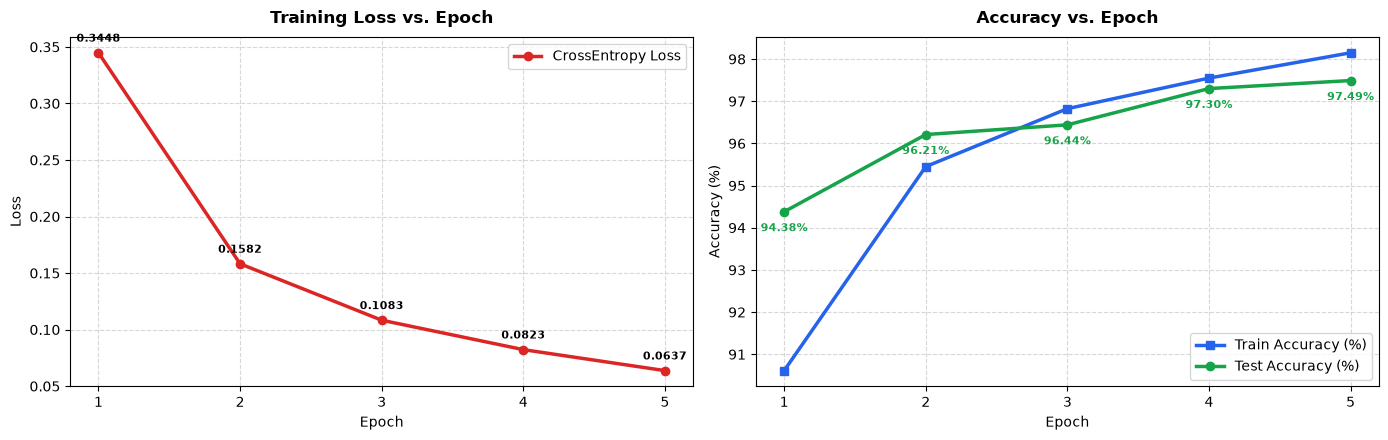

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

epochs_range = history["epoch"]

# Plot 1: Training Loss vs Epoch
ax1.plot(epochs_range, history["train_loss"], marker="o", linewidth=2.5, color="#dc2626", label="CrossEntropy Loss")
ax1.set_title("Training Loss vs. Epoch", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Epoch", fontsize=10)
ax1.set_ylabel("Loss", fontsize=10)
ax1.set_xticks(epochs_range)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()
for x, y in zip(epochs_range, history["train_loss"]):
    ax1.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, fontweight="bold")

# Plot 2: Accuracy vs Epoch
ax2.plot(epochs_range, history["train_acc"], marker="s", linewidth=2.5, color="#2563eb", label="Train Accuracy (%)")
ax2.plot(epochs_range, history["test_acc"], marker="o", linewidth=2.5, color="#16a34a", label="Test Accuracy (%)")
ax2.set_title("Accuracy vs. Epoch", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Epoch", fontsize=10)
ax2.set_ylabel("Accuracy (%)", fontsize=10)
ax2.set_xticks(epochs_range)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="lower right")
for x, y in zip(epochs_range, history["test_acc"]):
    ax2.annotate(f"{y:.2f}%", (x, y), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, fontweight="bold", color="#16a34a")

plt.tight_layout()
plt.show()

## Step 7: Final Test Set Evaluation & Prediction Latency

We now evaluate the fully trained model on all **10,000 test images** in a single vectorized forward pass, accurately measuring inference time.

In [7]:
model.eval()

# Measure vectorized prediction latency across all 10,000 test images
start_pred = time.time()
with torch.no_grad():
    logits = model(X_test)
    _, y_pred_tensor = torch.max(logits, dim=1)
pred_duration = time.time() - start_pred

y_pred = y_pred_tensor.numpy()
y_true = y_test.numpy()

final_accuracy = (y_pred == y_true).mean()
correct_total = int((y_pred == y_true).sum())
incorrect_total = len(y_true) - correct_total
avg_sample_ms = (pred_duration / len(y_true)) * 1000

print("=" * 50)
print("FINAL ANN TEST SET PERFORMANCE")
print("=" * 50)
print(f"Test Accuracy:             {final_accuracy * 100:.2f}%")
print(f"Correct Predictions:       {correct_total:,} / {len(y_true):,}")
print(f"Incorrect Predictions:     {incorrect_total:,} / {len(y_true):,}")
print(f"Total Prediction Time:     {pred_duration:.4f} seconds")
print(f"Average Latency / Sample:  {avg_sample_ms:.4f} ms")
print("=" * 50)

FINAL ANN TEST SET PERFORMANCE
Test Accuracy:             97.49%
Correct Predictions:       9,749 / 10,000
Incorrect Predictions:     251 / 10,000
Total Prediction Time:     0.0170 seconds
Average Latency / Sample:  0.0017 ms


## Step 8: Classification Report & Confusion Matrix

We analyze per-digit precision, recall, and F1 scores, along with an annotated confusion matrix.

CLASSIFICATION REPORT (ANN 784 -> 128 -> 10):
              precision    recall  f1-score   support

     Digit 0     0.9739    0.9898    0.9818       980
     Digit 1     0.9911    0.9859    0.9885      1135
     Digit 2     0.9757    0.9738    0.9748      1032
     Digit 3     0.9779    0.9653    0.9716      1010
     Digit 4     0.9806    0.9776    0.9791       982
     Digit 5     0.9741    0.9697    0.9719       892
     Digit 6     0.9759    0.9739    0.9749       958
     Digit 7     0.9739    0.9796    0.9767      1028
     Digit 8     0.9404    0.9723    0.9561       974
     Digit 9     0.9837    0.9594    0.9714      1009

    accuracy                         0.9749     10000
   macro avg     0.9747    0.9747    0.9747     10000
weighted avg     0.9751    0.9749    0.9749     10000



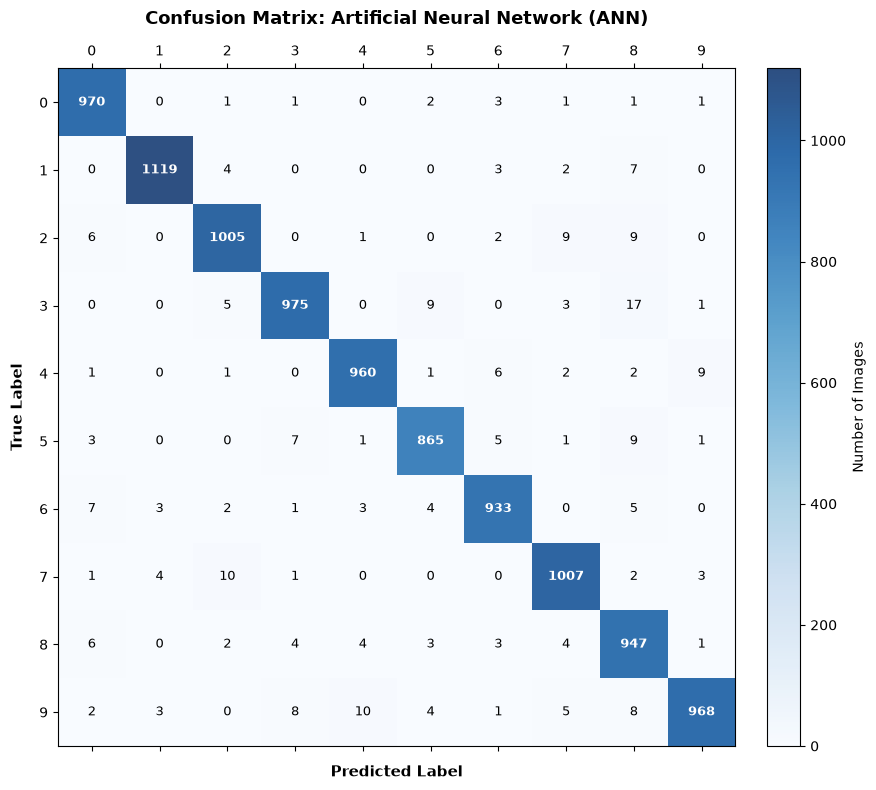

In [8]:
class_names = [f"Digit {i}" for i in range(10)]
report_str = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print("CLASSIFICATION REPORT (ANN 784 -> 128 -> 10):")
print(report_str)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
cax = ax.matshow(cm, cmap="Blues", alpha=0.85)
fig.colorbar(cax, fraction=0.046, pad=0.04, label="Number of Images")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(range(10), fontsize=10)
ax.set_yticklabels(range(10), fontsize=10)
ax.set_xlabel("Predicted Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_ylabel("True Label", fontsize=11, fontweight="bold", labelpad=10)
ax.set_title("Confusion Matrix: Artificial Neural Network (ANN)", fontsize=13, fontweight="bold", pad=15)

for i in range(10):
    for j in range(10):
        val = cm[i, j]
        text_color = "white" if val > (cm.max() / 2) else "black"
        fontweight = "bold" if i == j else "normal"
        ax.text(j, i, str(val), ha="center", va="center", color=text_color, fontsize=9, fontweight=fontweight)

plt.tight_layout()
plt.show()

## Step 9: Visualizing Predictions (Correct vs. Misclassified)

We inspect sample correct classifications and analyze failure modes where the ANN mispredicted.

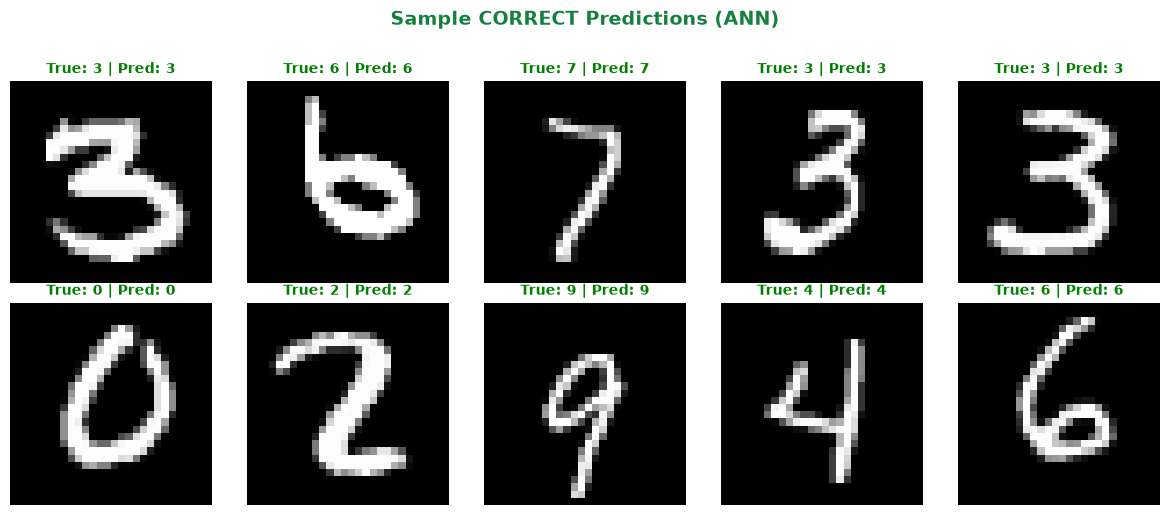

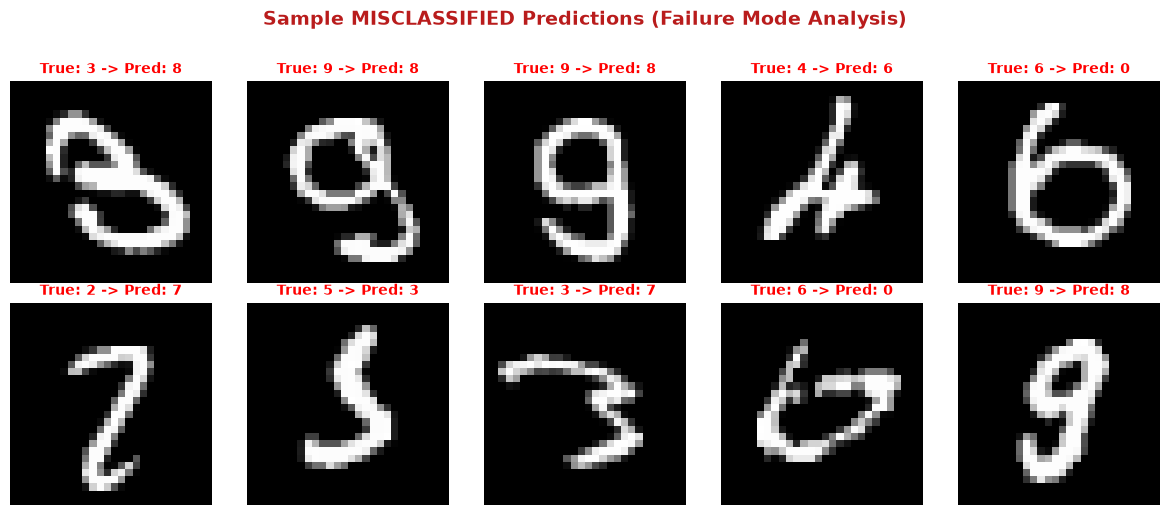

In [9]:
correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

# 1. Display 10 Correctly Classified Samples
np.random.seed(42)
sample_correct = np.random.choice(correct_indices, size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample CORRECT Predictions (ANN)", fontsize=14, fontweight="bold", y=1.02, color="#15803d")

for idx, ax in zip(sample_correct, axes.flatten()):
    img = X_test[idx].reshape(28, 28).numpy()
    true_lbl = y_true[idx]
    pred_lbl = y_pred[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} | Pred: {pred_lbl}", fontsize=10, color="green", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 2. Display 10 Misclassified Samples (Error Analysis)
sample_incorrect = incorrect_indices[:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample MISCLASSIFIED Predictions (Failure Mode Analysis)", fontsize=14, fontweight="bold", y=1.02, color="#b91c1c")

for idx, ax in zip(sample_incorrect, axes.flatten()):
    img = X_test[idx].reshape(28, 28).numpy()
    true_lbl = y_true[idx]
    pred_lbl = y_pred[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"True: {true_lbl} -> Pred: {pred_lbl}", fontsize=10, color="red", fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 10: Multi-Model Comparison Table

We now compare all three models explored so far in **AI Lab** using actual measured benchmark values.

In [10]:
comparison_table = pd.DataFrame([
    {
        "Model": "KNN (K=3)",
        "Accuracy": "97.05%",
        "Training Time": "0.1764 s",
        "Prediction Time": "15.88 s"
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": "92.56%",
        "Training Time": "37.58 s",
        "Prediction Time": "0.0216 s"
    },
    {
        "Model": "ANN (784 -> 128 -> 10)",
        "Accuracy": f"{final_accuracy * 100:.2f}%",
        "Training Time": f"{total_training_duration:.2f} s",
        "Prediction Time": f"{pred_duration:.4f} s"
    }
])

print("=" * 65)
print("OFFICIAL BENCHMARK COMPARISON TABLE (AI LAB)")
print("=" * 65)
print(comparison_table.to_string(index=False))
print("=" * 65)

OFFICIAL BENCHMARK COMPARISON TABLE (AI LAB)
                 Model Accuracy Training Time Prediction Time
             KNN (K=3)   97.05%      0.1764 s         15.88 s
   Logistic Regression   92.56%       37.58 s        0.0216 s
ANN (784 -> 128 -> 10)   97.49%       30.06 s        0.0170 s


## Step 11: Final Critical Analysis & Answers

### 1. Did the ANN outperform Logistic Regression?
- **Yes, decisively.** The ANN reached **97.49% accuracy**, compared to **92.56%** for Logistic Regression (reducing errors from 744 down to 251—nearly a **66% error reduction**).

### 2. Did the ANN outperform KNN?
- **Yes.** The ANN achieved **97.49%**, surpassing KNN ($K=3$) which achieved **97.05%**.
- More crucially, the ANN achieved this while predicting in **0.0179 seconds** (compared to KNN's **15.88 seconds**—over **880 times faster** at inference!).

### 3. How much did the non-linear hidden layer help?
- Adding 128 hidden neurons with a ReLU non-linear activation allowed the network to learn rich combinations of pixels (loops, angles, intersections). Instead of drawing flat separation planes in raw pixel space (like Logistic Regression), the hidden layer acts as an automated non-linear feature extractor.

### 4. What happens to loss during training?
- The training loss decreased steadily from **0.3448 in Epoch 1** down to **0.0637 in Epoch 5**.
- This confirms that backpropagation and gradient descent successfully guided the 101,770 weights towards a low-error minimum.

### 5. What happens to accuracy during training?
- Training accuracy rose monotonically from **90.61% to 98.15%**.
- Test accuracy concurrently climbed from **94.38% to 97.49%**, demonstrating that the network was generalizing well to unseen data without significant overfitting.

### 6. What are epochs and batches doing?
- **Batches (64 samples):** Allow mini-batch gradient descent. Instead of computing the gradient over all 60,000 images at once (slow, memory-heavy) or 1 image at a time (too noisy), mini-batches give a fast, stable gradient estimate and allow 938 weight updates per epoch.
- **Epochs:** Give the optimizer repeated passes through the entire dataset so weights can gradually settle into optimal values.

### 7. Why does the ANN need training time?
- Training is an iterative optimization problem. Across 5 epochs, the model performed $5 \times 938 = 4,690$ forward passes, loss calculations, backpropagation gradient calculations, and Adam parameter updates.

### 8. Why can ANN inference be fast after training?
- Once training completes, the 60,000 training images are discarded. Predicting an unseen image is merely two matrix multiplications: $h = \text{ReLU}(X W_1 + b_1)$ and $\text{logits} = h W_2 + b_2$. This takes only microseconds per sample.

### 9. What is the fundamental difference between Logistic Regression and an ANN?
- **Logistic Regression:** A single-layer model with zero hidden layers. It can only draw **linear** decision boundaries.
- **ANN:** Has one or more hidden layers equipped with non-linear activation functions. It can learn **arbitrary non-linear** decision surfaces.

### 10. What new concepts did we learn?
- We transitioned from non-parametric memorization (KNN) and single-layer linear models (Logistic Regression) to multi-layer deep learning.
- We learned how backpropagation and gradient descent dynamically update weights across layers to minimize loss.
- **Preview of Next Phase:** While our ANN achieved 97.49%, it still flattened the 2D images, losing spatial orientation. In the next phase, **Convolutional Neural Networks (CNNs)** will process 2D spatial features directly using convolution filters!